## Relationship between Exponential random variables and Gamma random variables

In [101]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats

## Q1
Let us find the relationship between random variables generated from Exponential distribution and a random variable generated from Gamma distribution. To make sure thing set up correctly, we set lambda = 2, and we want you to generate 10 random values from np.random.exponential() function. We want you to find three things:

1. **The appropriate value for r(the number of events you're waiting for) for gamma distribution.**

2. **The sum of Exponential values and store it in variable "expo".**

3. **A random variable generated from np.random.gamma() function and store it in variable "gamma".**

In [102]:
# the number of exponential random variable
n = 10
# lambda
lam = 2

In [103]:
r = 10 # SOLUTION
#Use np.random.exponential(), there are two parameters: 'scale' should be 1/lambda, 'size' should be the number of values you want to generate
expo = sum(np.random.exponential(scale = 1/lam, size = n)) # SOLUTION
#Use np.random.gamma(), there are two parameters: 'scale' should be 1/lambda, 'shape' where you put 'r' 
gamma = np.random.gamma(shape = r, scale = 1/lam) # SOLUTION

In [105]:
bool(r == 10)

True

In [106]:
assert (isinstance(expo, np.floating) or isinstance(expo, float))

In [107]:
assert (isinstance(gamma, np.floating) or isinstance(gamma, float))

You probably notice that the two values are not equal to each other, or maybe those two values are far different from another. Why did it fail to satisfy this?

X ~ Exponential(λ), Y ~ Gamma(10, λ)  ===> X_1 + X_2 + ... + X_10  = Y

That is because X_1, X_2, ..., X_10 and Y are random variables, they are not specific values we generated in Q1. So, to verify this equation, we will have to repeat the above step several times. 

## Q1.2
Here are your tasks:
Let us ran 20000 simulations, each iteration, you should generate sum of 10 random values from Exponential distribution with lambda = 2 and one random value from Gamma distribution with r = value found in Q1, lambda = 2. Generate two histograms, overlap them to see if they fit on each other.

You can import any tool you need to generate those two histograms, as long you don't change any variable that are given with a value.

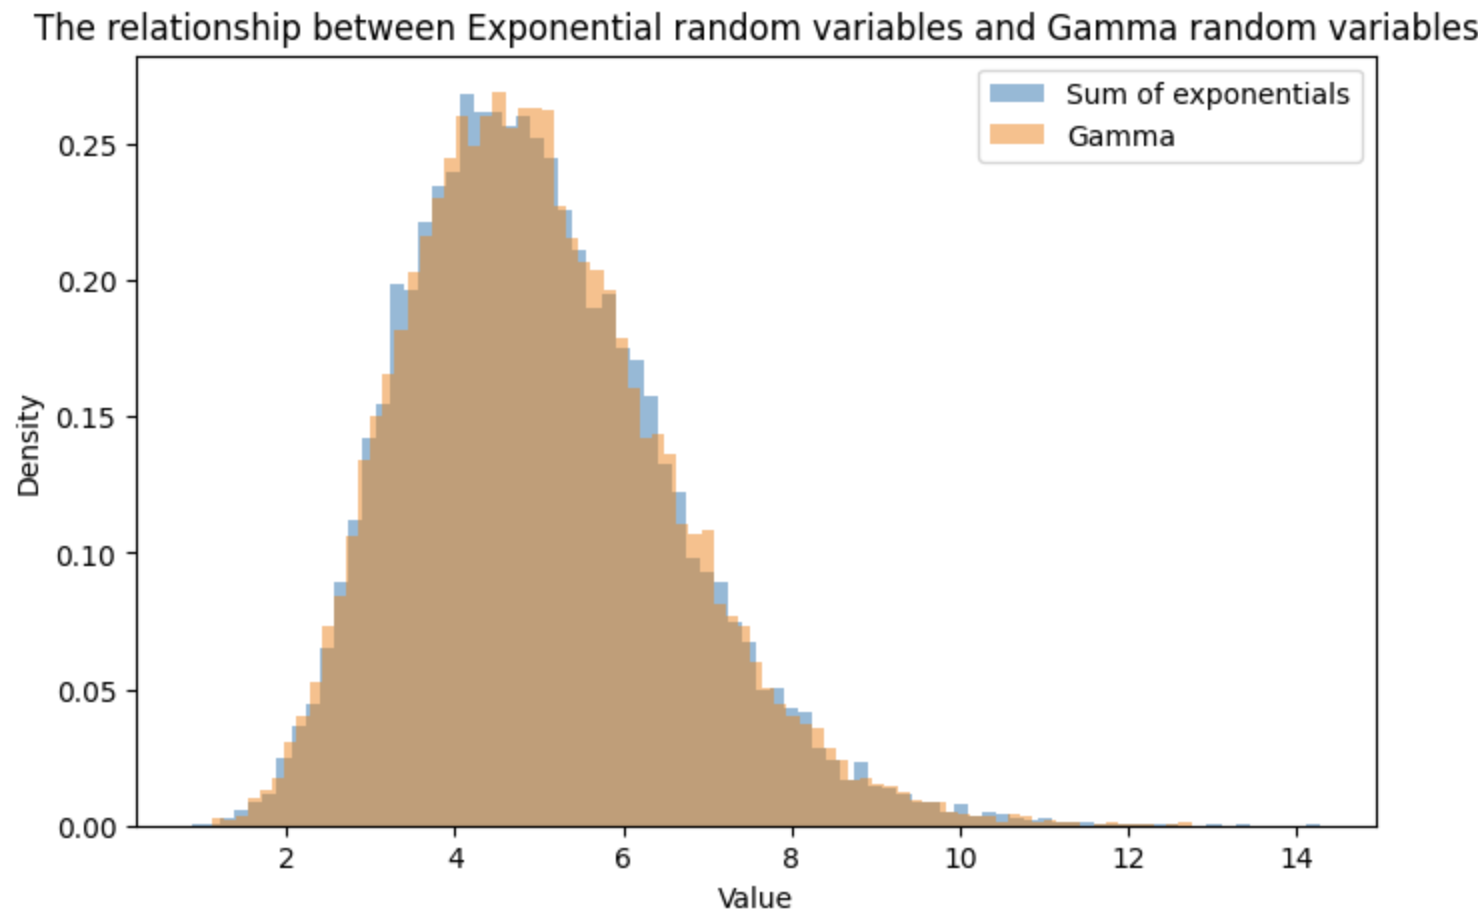

In [108]:
from IPython.display import Image, display
display(Image("Q1_2.png"))

You graph should look like this, doesn't have to look eactly the same.

In [109]:
N = 20000     # number of simulations
n = 10         # number of exponential RVs
lam = 2       # rate parameter
r_1 = r         # used for gamma distribution

In [110]:
#Create your own graph, no test for this, but you will need this code for next problem.

AH! Now we see that two distributions look very similar to each other, and they almost fully overlap with each other. We have verify X_1 + X_2 + ... + X_10  = Y with code.

Now, change the lambda from 2 to 10, then run your code that generate the graph. Choose an option below that best answer this question: Do the overall values of the distributions become larger or smaller when λ = 10 compared to when λ = 2? Store you answer(uppercase) in variable "Q1_2".

- A). They became smaller
- B). They became bigger
- C). They didn't change
- D). I don't know

In [111]:
Q1_2 = 'A' # SOLUTION

str

In [112]:
assert isinstance(Q1_2, str) 

## Q2

In the lesson notes, we told you that the Exponential distribution has a unique property called the **Memoryless property**, which states that:

$P(X > s+t \mid X > s) = P(X > t)$

where $X∼Exp(λ)$ and $s$ and $t$ are any non-negative values. We didn’t prove this property in the notes, so in this problem, you will verify it using code.

Generate 500000 random values from an Exponential distribution with $λ = 2$. Then compute $P(X > s+t \mid X > s)$ and $P(X > t)$ for a list of values of $t$ and a fixed value of $s$.

Store the results for $P(X > s+t \mid X > s)$ in a list named **conditional_probability**, and store the results for $P(X > t)$ in a list named **simplifpy_probability**.




In [113]:
n = 500000
lam = 2
t_values = [0.1, 0.5, 1.0, 2.0, 3.0]
s = 1
conditional_probability = []
simplify_probability = []
#we use this to make sure the result is a certain number, as long as you number fall into certain range, then 
#it is good.
rng = np.random.default_rng(seed=1)

def find_probability(n, lam, t_values, s, rng):
    conditional_probability = []
    simplify_probability = []
    for t in t_values:
        values = rng.exponential(scale=1/lam, size=n)
        s_prob = np.mean(values > t)
        c_prob = np.mean(values > (t+s))/np.mean(values > s)
        conditional_probability.append(c_prob)
        simplify_probability.append(s_prob)
    return conditional_probability, simplify_probability

In [114]:
conditional_probability, simplify_probability = find_probability(n, lam, t_values, s, rng)# SOLUTION

In [115]:
bool(len(conditional_probability) == 5)

True

In [116]:
bool(len(simplify_probability) == 5)

True

In [117]:
bool(np.abs(conditional_probability[0] - simplify_probability[0]) <= 0.01)

True

Now you see that P(X > s+t | X > s) = P(X > t) is true for the Exponential distribution, though the values might vary by little. The gaps become smaller we generate more random values from the distribution.

## Q2.2 

Generate 500000 random values from an Gamma distribution with $λ = 2$ and $r = 10$. Then compute $P(X > s+t \mid X > s)$ and $P(X > t)$ for a list of values of $t$ and a fixed value of $s$.

Store the results for $P(X > s+t \mid X > s)$ in a list named **gamma_cond_probability**, and store the results for $P(X > t)$ in a list named **gamma_simp_probability**.

In [118]:
gamma_n = 500000
gamma_lam = 2
gamma_r = 10
gamma_t_values = [1, 2, 4, 7, 12]
gamma_s = 5


rng2 = np.random.default_rng(seed=1)

def gamma_find_probability(gamma_n, gamma_lam, gamma_r, gamma_t_values, gamma_s, rng2):
    gamma_cond_probability = []
    gamma_simp_probability = []
    for gt in gamma_t_values:
        gamma_values = rng2.gamma(shape = gamma_r, scale=1/gamma_lam, size=gamma_n)
        gamma_s_prob = np.mean(gamma_values > gt)
        #first method
        #gamma_c_prob = np.mean(gamma_values > (gt+gamma_s))/np.mean(gamma_values > gamma_s)
        #second method
        condition = gamma_values>gamma_s
        gamma_c_prob = np.mean(gamma_values[condition] > gamma_s+gt)
        gamma_cond_probability.append(gamma_c_prob)
        gamma_simp_probability.append(gamma_s_prob)
    return gamma_cond_probability, gamma_simp_probability


In [119]:
gamma_cond_probability, gamma_simp_probability = gamma_find_probability(gamma_n, gamma_lam, gamma_r, gamma_t_values, gamma_s, rng2) #SOLUTION

In [120]:
bool(len(gamma_cond_probability) == 5)

True

In [121]:
bool(len(gamma_simp_probability) == 5)

True

## Q2.3
Which of the following best explains why the Exponential distribution is memoryless while the Gamma distribution is not?

- A). The Gamma distribution has a larger mean than the Exponential distribution, so it cannot be memoryless.

- B). The Exponential distribution is continuous and the Gamma distribution is discrete, so only the Exponential distribution can be memoryless.

- C). The Exponential distribution models the waiting time for only one event,while the Gamma distribution models the waiting time for multiple events, so the past affects the remaining waiting time.

- D). The Exponential distribution models the waiting time for one event, so the past does not matter. The Gamma distribution models the waiting time for multiple events, so the past affects the remaining waiting time.

Store your answer(uppercase) in variable "q2_3".

In [122]:
q2_3 = 'C' #SOLUTION

In [123]:
assert isinstance(q2_3, str) 

**Then, include the following two cells:**

To submit your assignment:

1. Select `Kernel -> Restart & Run All` to ensure that you have executed all cells, including the test cells.
2. Read through the notebook to make sure everything is fine and all tests passed.
3. Run the cell below to run all tests, and make sure that they all pass.
4. Download your notebook using `File -> Download as -> Notebook (.ipynb)`, then upload your notebook to Gradescope.
5. Stick around while the Gradescope autograder grades your work. Make sure you see that all tests have passed on Gradescope.
6. Check that you have a confirmation email from Gradescope and save it as proof of your submission.

In [ ]:
# For your convenience, you can run this cell to run all the tests at once!
grader.check_all()